<div style="display: flex; justify-content: flex-start; align-items: center;">
    <a href="https://colab.research.google.com/github/msfasha/307307-BI-Methods-Generative-AI/blob/main/20261/Module%203%20-%20Memory/Module3_Memory_lab.ipynb" target="_blank">
        <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab" style="height: 25px;">
    </a>
</div>

<div style="background:#F5EDF4; border-top:3px solid #A83296; padding:15px; border-radius:0 0 8px 8px">
<h1 style="color:#493347; margin:0">Lab — Memory (Module 3)</h1>
<p style="color:#655263; margin:4px 0 0 0">Intro to Generative AI / Agentic AI — University of Petra</p>
</div>

**Course:** 307307 BI Methods for Generative AI (Agentic AI half)  
**Reference:** Grootendorst &amp; Alammar, *An Illustrated Guide to AI Agents* (O'Reilly, 2026), Chapter 4.

In Module 2 the `TinyAgent` got a brain — but it forgets everything the instant it answers. Today we give it **memory** so it can hold a real conversation.

**This is a run-and-observe lab.** Most cells are already written — your job is to **run each cell and read the output**. There is one small exercise near the end.

**What you will see:**
1. The agent **forgets** your name (the problem).
2. We add a tiny **`Memory`** module.
3. The agent now **remembers** across turns.
4. A quick look at **trimming** memory to fit the context window.
5. A tiny **RAG**: the agent looks up facts in a small knowledge base using embeddings and a **vector store**.

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Part 0 — Setup (just run these)</h2>
</div>

The first cell re-creates the `LLM` brain from Module 2 so this notebook runs on its own. You do not need to change it — just run it.

In [ ]:
# In Google Colab, remove the leading # to install. Locally, run once.
# %pip install -q openai

In [ ]:
import os
from getpass import getpass
from dataclasses import dataclass
from openai import OpenAI

if not os.environ.get('GEMINI_API_KEY'):
    os.environ['GEMINI_API_KEY'] = getpass('Paste your Gemini API key (hidden): ')

MODEL = 'gemini-3.8-flash'   # a model enabled on your account (your Practical lab uses this one)
BASE_URL = 'https://generativelanguage.googleapis.com/v1beta/openai/'

# --- The brain from Module 2 (just run it) ---
@dataclass
class Response:
    content: str = ''
    reasoning: str | None = None
    metadata: dict | None = None

class LLM:
    def __init__(self, model=MODEL, base_url=BASE_URL, api_key=None, temperature=0.0):
        self.model, self.temperature = model, temperature
        self.client = OpenAI(api_key=api_key or os.environ['GEMINI_API_KEY'], base_url=base_url)
    def generate(self, messages):
        r = self.client.chat.completions.create(model=self.model, messages=messages,
                                                temperature=self.temperature)
        m = r.choices[0].message
        return Response(content=m.content,
                        metadata={'prompt_tokens': r.usage.prompt_tokens,
                                  'completion_tokens': r.usage.completion_tokens})

llm = LLM()
print('Ready. Model:', MODEL)

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Part 1 — The problem: the agent forgets</h2>
</div>

Here is a simple agent *without* memory (like Module 2). Watch it forget who you are between two questions.

In [ ]:
class ForgetfulAgent:
    def __init__(self, llm):
        self.llm = llm
    def run(self, task):
        # Only the current question is sent - nothing from before.
        return self.llm.generate([{'role': 'user', 'content': task}]).content

agent = ForgetfulAgent(llm)
print(agent.run('Hi! My name is Sara and I study Business Intelligence.'))
print('---')
print(agent.run('What is my name and what do I study?'))   # It will not know!

It has no idea — not because it 'forgot', but because the second call **never received** the first message. Every call starts from a blank slate.

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Part 2 — The Memory module</h2>
</div>

Memory is just a **list of messages** we keep adding to. Two methods: `add()` to store a message, and `get_messages()` to hand the whole history to the LLM. That's it — about 15 lines.

In [ ]:
class Memory:
    """Stores the conversation history as a list of messages."""
    def __init__(self):
        self.messages = []

    def add(self, role, content):
        # Save one message (role is 'system', 'user', or 'assistant').
        self.messages.append({'role': role, 'content': content})

    def get_messages(self):
        # Return the full history to send to the LLM.
        return self.messages

print('Memory module defined.')

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Part 3 — The TinyAgent, now with memory</h2>
</div>

The only change from Module 2: before answering, we **add the user's message to memory**, send the **whole history** to the brain, then **add the reply to memory**. Run it and ask a follow-up.

<div align="center">
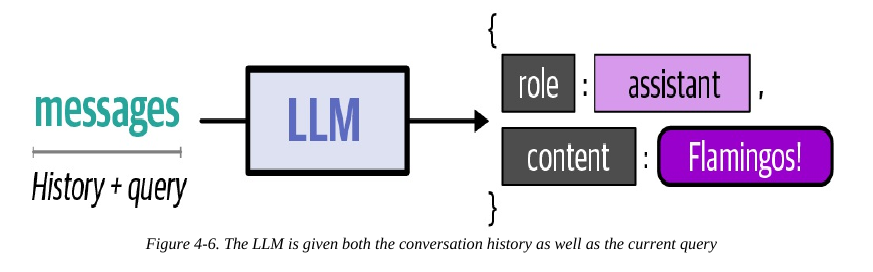
<br><span style="color:#6E6E6E; font-size:90%"><i>The conversation history (plus the new query) is sent to the LLM each turn (Figure 4-6). An Illustrated Guide to AI Agents (O'Reilly, 2026)</i></span>
</div>

In [ ]:
class TinyAgent:
    """TinyAgent with memory: it remembers the conversation."""
    def __init__(self, llm, memory, system_prompt='You are a helpful assistant.'):
        self.llm = llm
        self.memory = memory
        self.memory.add('system', system_prompt)

    def run(self, task):
        self.memory.add('user', task)                      # 1. remember the question
        response = self.llm.generate(self.memory.get_messages())  # 2. answer using full history
        self.memory.add('assistant', response.content)     # 3. remember the answer
        return response.content

agent = TinyAgent(llm=llm, memory=Memory())
print(agent.run('Hi! My name is Sara and I study Business Intelligence.'))
print('---')
print(agent.run('What is my name and what do I study?'))   # Now it knows!

It remembers — because this time the first message was included in the second call. Let's look at exactly what the agent is holding in memory.

In [ ]:
for msg in agent.memory.get_messages():
    print(f"{msg['role']:>9}: {msg['content'][:70]}")

That whole list is sent to the LLM on every turn. The model does not have internal memory — **we tell it** what the conversation was.

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Part 4 — Keeping memory small: trimming</h2>
</div>

A conversation can grow past the model's **context window**. One simple fix is **trimming**: keep only the last few turns. Below, `TrimmingMemory` keeps the system message plus the **last 2 turns** (4 messages). Run it and watch the early turns disappear.

<div align="center">
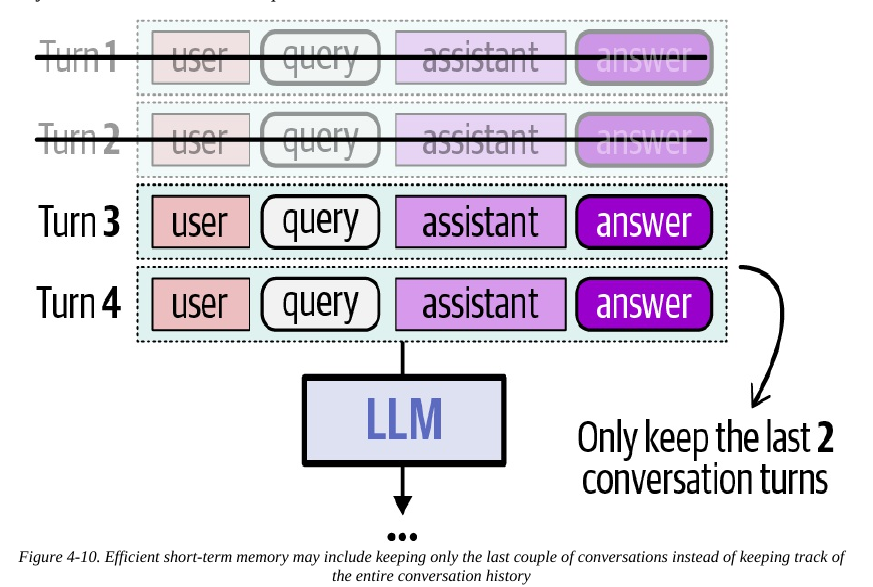
<br><span style="color:#6E6E6E; font-size:90%"><i>Trimming keeps only the most recent turns to fit the context window (Figure 4-10). An Illustrated Guide to AI Agents (O'Reilly, 2026)</i></span>
</div>

In [ ]:
class TrimmingMemory(Memory):
    """Keeps the system message plus the last 2 user/assistant turns."""
    def add(self, role, content):
        super().add(role, content)
        system = [m for m in self.messages if m['role'] == 'system']
        turns  = [m for m in self.messages if m['role'] != 'system']
        self.messages = system + turns[-4:]   # last 4 non-system messages = 2 turns

agent = TinyAgent(llm=llm, memory=TrimmingMemory())
agent.run('My name is Sara.')
agent.run('I study Business Intelligence.')
agent.run('What is 1 + 1?')
agent.run('What is 2 + 2?')

print('Memory now holds only:')
for msg in agent.memory.get_messages():
    print(f"{msg['role']:>9}: {msg['content'][:60]}")

Only the most recent turns survive — notice the early "My name is Sara" message is gone. Trimming keeps memory small, but it can **drop important information** from earlier. (Another option is **summarization** — ask an LLM to compress old turns into a short summary; it is covered in the slides. And for outside knowledge, **RAG** retrieves relevant documents — you will build a tiny one in Part 5.)

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Part 5 — Long-term memory: a tiny RAG</h2>
</div>

So far, memory held the **conversation**. But an agent often needs knowledge that was never part of the conversation — a company handbook, course policies, a product manual. We cannot paste everything into every prompt (the context window is limited), so we **retrieve only the few pieces that matter**. This is **RAG** — *Retrieval-Augmented Generation*.

In this part you build the four RAG steps yourself, in a few lines of Python:
1. **Embed** — turn each text into a list of numbers (an *embedding*), so that texts with similar meaning get similar numbers.
2. **Retrieve** — embed the question too, then find the stored texts whose embeddings are most similar to it.
3. **Augment** — paste the retrieved texts into the prompt as context.
4. **Generate** — the LLM answers using that added context.

Our knowledge base is the handbook of an **invented** place, *Nova Café*. It is fictional on purpose, so the model cannot already know it.

In [ ]:
# A tiny, FICTIONAL knowledge base: the handbook of "Nova Café" (invented for this lab).
DOCS = [
    "Nova Café is open from 8:00 to 22:00 on weekdays and from 10:00 to 23:00 on weekends.",
    "Unopened merchandise, such as mugs and coffee bags, can be returned within 14 days with a receipt.",
    "Opened coffee bags cannot be returned, but they can be exchanged within 7 days if the coffee is defective.",
    "Loyalty members earn 1 point for every 1 JD spent. Every 100 points give one free drink.",
    "Gold members (500 or more points per year) get a 10% discount on merchandise and a 30-day return window for unopened merchandise.",
    "Free Wi-Fi is available. The password is printed on every receipt.",
    "All pastries are baked in a kitchen that also handles nuts, sesame and gluten.",
    "Catering orders for 20 or more people must be placed at least 48 hours in advance.",
]
print(len(DOCS), 'documents in the knowledge base')

**Step 1 — Embed.** An *embedding model* is a different kind of model from the chat LLM: it does not write text, it converts text into a list of numbers. We use Gemini's embedding model through the same client as the LLM.

One rule matters: use the **same** embedding model for the documents and for the questions. Vectors produced by different models cannot be compared.

In [ ]:
EMBED_MODEL = 'gemini-embedding-001'   # Gemini's text embedding model

def embed(text):
    """Turn a piece of text into a list of numbers (its embedding)."""
    r = llm.client.embeddings.create(model=EMBED_MODEL, input=text)
    return r.data[0].embedding

v = embed(DOCS[1])
print('One embedding is a list of', len(v), 'numbers. The first five:')
print([round(x, 3) for x in v[:5]])

**Measuring "similar".** *Cosine similarity* compares the **direction** of two vectors: `1` means they point the same way, `0` means they are at right angles, and `-1` means they point in opposite directions. For embeddings, a **higher** score means more similar meaning. Try the toy vectors first, then use the same function on real embeddings.

In [ ]:
import math

def cosine_similarity(a, b):
    """1 = same direction, 0 = at right angles, -1 = opposite directions."""
    dot = sum(x * y for x, y in zip(a, b))
    length_a = math.sqrt(sum(x * x for x in a))
    length_b = math.sqrt(sum(y * y for y in b))
    return dot / (length_a * length_b)

# Toy vectors with only two numbers, so you can see what the score means:
print(cosine_similarity([1, 0], [1, 0]))    # same direction
print(cosine_similarity([1, 0], [0, 1]))    # at right angles
print(cosine_similarity([1, 0], [-1, 0]))   # opposite directions

**Step 2 — Retrieve.** A *vector store* keeps each text next to its vector and answers one question: *which stored vectors are closest to this query vector?* Ours compares the question with **every** stored vector, which is fine for 8 documents.

In [ ]:
class VectorStore:
    """Keeps (text, vector) pairs and finds the stored texts most similar to a query."""
    def __init__(self):
        self.items = []                          # a list of (text, vector) pairs

    def add(self, text):
        self.items.append((text, embed(text)))   # Step 1: embed the document and keep it

    def search(self, query, k=3):
        q = embed(query)                         # embed the question with the SAME model
        scored = [(cosine_similarity(q, vec), text) for text, vec in self.items]
        scored.sort(reverse=True)                # highest similarity first
        return scored[:k]                        # Step 2: the k most similar documents

store = VectorStore()
for doc in DOCS:
    store.add(doc)
print(len(store.items), 'documents stored')

In [ ]:
def show(query, k=3):
    print('QUESTION:', query)
    for score, text in store.search(query, k):
        print(f'  {score:.3f}  {text}')
    print()

show('How many points do I need for a free drink?')
show('What time do you close on Saturday?')
show('Who won the football match yesterday?')   # nothing in the handbook is about this

Look at the three searches.
- Does the right document come first even when the question uses different words from the document?
- For the unrelated football question, the store **still returns its three closest documents**. A vector search always returns its nearest items; it does not know whether any of them is actually relevant. Compare the scores with the earlier questions. This is why RAG systems often add a minimum-score rule, or tell the model it is allowed to answer "I don't know".

**Steps 3 and 4 — Augment and Generate.** The function below retrieves the 2 most similar documents, puts them into the prompt as *context*, and asks the LLM to answer using only that context. We ask the same question twice: once without retrieval and once with it.

In [ ]:
def answer_with_rag(question, k=2):
    hits = store.search(question, k)                           # Steps 1-2: embed + retrieve
    context = '\n'.join(f'- {text}' for _, text in hits)       # Step 3: augment the prompt
    prompt = ('Answer the question using ONLY the context below. '
              "If the context does not contain the answer, say you don't know.\n\n"
              f'Context:\n{context}\n\nQuestion: {question}')
    return llm.generate([{'role': 'user', 'content': prompt}]).content   # Step 4: generate

question = 'How many points do I need for a free drink at Nova Café?'
print('WITHOUT retrieval:', llm.generate([{'role': 'user', 'content': question}]).content)
print()
print('WITH retrieval   :', answer_with_rag(question))

**What happened.** Without retrieval the model has no way of knowing the rules of a fictional café, so it may guess or say it does not know. With RAG it received the most relevant documents inside the prompt and could answer from them.

Notice what did **not** change: the model itself. RAG adds facts to the **prompt**. If retrieval brings back the wrong documents, the answer will be wrong too.

**From our `VectorStore` to a vector database.** A *vector database* does the same job as our class: it stores vectors together with their original text (and often extra information called *metadata*, such as the source or the date) and returns the most similar ones. It is built for scale:
- Comparing a question with **every** vector becomes slow with millions of vectors. Vector databases build an **index** that finds the *approximately* nearest vectors much faster. This is called approximate nearest-neighbour search: a small chance of missing a true nearest neighbour in exchange for a large gain in speed.
- They can **filter by metadata**, for example "only documents from this source".
- They keep data on disk, allow updates and deletes, and serve many users at once.

Examples: Chroma, Qdrant, Pinecone, Weaviate, Milvus, and the *pgvector* extension for PostgreSQL. (FAISS is a similarity-search *library* rather than a full database.)

**Optional — the same idea with a real vector database (Chroma).** Run this only if you have time. It installs Chroma, stores the same documents with the same embeddings, and runs a similar search. Chroma reports a **distance** (here, `1 - cosine similarity`), so **lower means closer**.

In [ ]:
# In Google Colab, remove the leading # to install. Locally, run once.
# %pip install -q chromadb
import chromadb   # tested with chromadb 1.5.x

chroma = chromadb.Client()                               # an in-memory vector database
col = chroma.create_collection('nova_cafe', metadata={'hnsw:space': 'cosine'})
col.add(ids=[str(i) for i in range(len(DOCS))],
        documents=DOCS,
        embeddings=[embed(d) for d in DOCS])             # we supply the embeddings ourselves

res = col.query(query_embeddings=[embed('What time do you close on Saturday?')], n_results=3)
for text, dist in zip(res['documents'][0], res['distances'][0]):
    print(f'{dist:.3f}  {text}')                         # lower distance = closer

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Exercise</h2>
</div>

**Task A.** Create a `TinyAgent` with a **plain `Memory`** and a `system_prompt` that gives it a personality (for example: *"You always answer like a friendly pirate."*). Have a **3-message conversation** and confirm it stays in character *and* remembers earlier details.

**Task B (think, no code).** In a comment, explain one risk of using `TrimmingMemory` for a long tutoring conversation.

**Task C.** Add a **new document** to the knowledge base (for example: *"Students get a 5% discount on drinks with a university ID."*), then ask `answer_with_rag` a question that only the new document can answer.

**Task D (think, no code).** In a comment, say why the documents and the questions must be embedded with the **same** embedding model.

Fill in the `# YOUR CODE HERE` lines, then check the solution below.

In [ ]:
# YOUR CODE HERE
# Task A:
# pirate = TinyAgent(llm=llm, memory=Memory(), system_prompt=...)
# print(pirate.run('Hi, my name is Sara.'))
# print(pirate.run('I love data science.'))
# print(pirate.run('What is my name and what do I love?'))

# Task B (answer in a comment): one risk of TrimmingMemory in a long conversation?
# Answer: ...

# Task C:
# store.add('Students get a 5% discount on drinks with a university ID.')
# print(answer_with_rag('Do students get a discount?'))

# Task D (answer in a comment): why the same embedding model for documents and questions?
# Answer: ...

**Solution** (try it yourself first):

In [ ]:
# --- Solution ---
# Task A
pirate = TinyAgent(llm=llm, memory=Memory(),
                   system_prompt='You always answer like a friendly pirate, but stay helpful.')
print(pirate.run('Hi, my name is Sara.'))
print(pirate.run('I love data science.'))
print(pirate.run('What is my name and what do I love?'))  # remembers, in character

# Task B
# TrimmingMemory only keeps the last few turns, so facts shared early in a long
# conversation (a student's name, their goal, an earlier answer) get dropped and
# the agent 'forgets' them. Summarization or retrieval would preserve the gist.

# Task C
store.add('Students get a 5% discount on drinks with a university ID.')
print(answer_with_rag('Do students get a discount?'))   # the new document is now retrievable

# Task D
# Each embedding model has its own "space" of numbers. Vectors from two different models
# are not comparable, so a question embedded with one model cannot be matched against
# documents embedded with another. Always embed documents and questions with the same model.

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Summary and what we built</h2>
</div>

Today you:
- Saw that LLMs are **stateless** — the agent forgot your name.
- Added a tiny **`Memory`** module (store + return the message history).
- Upgraded the `TinyAgent` so it **remembers** across turns.
- Used **`TrimmingMemory`** to keep memory within the context window.
- Built a tiny **RAG**: embeddings, a **`VectorStore`** that finds the most similar documents by cosine similarity, and a prompt that adds them as context.

```
TinyAgent/
  agent.py        <- updated: adds the user/assistant messages to memory each turn
  llm.py
  memory.py       <- new: Memory, TrimmingMemory (and, in this lab, a tiny VectorStore for RAG)
  trajectory.py
```

The agent can now hold a conversation — but it still can't **do** anything in the world. **Next module (Tools):** we let it take actions.

**Further reading:** *An Illustrated Guide to AI Agents*, Chapter 4 (Memory).